<a href="https://colab.research.google.com/github/RiddhiSinha123/Multilingual-search/blob/main/MIRACL_Multilingual_Search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q datasets huggingface_hub pandas numpy scikit-learn rank-bm25 sentence-transformers nltk indic-nlp-library

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.1/121.1 kB 7.9 MB/s eta 0:00:00


In [3]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import random

print("Libraries loaded!")

Libraries loaded!


In [4]:
from huggingface_hub import list_repo_files

files = list_repo_files(
    repo_id="miracl/miracl",
    repo_type="dataset"
)

for file in files[:100]:
    print(file)

.gitattributes
README.md
miracl-v1.0-ar/qrels/qrels.miracl-v1.0-ar-dev.tsv
miracl-v1.0-ar/qrels/qrels.miracl-v1.0-ar-train.tsv
miracl-v1.0-ar/topics/topics.miracl-v1.0-ar-dev.tsv
miracl-v1.0-ar/topics/topics.miracl-v1.0-ar-test-a.tsv
miracl-v1.0-ar/topics/topics.miracl-v1.0-ar-test-b.tsv
miracl-v1.0-ar/topics/topics.miracl-v1.0-ar-train.tsv
miracl-v1.0-bn/qrels/qrels.miracl-v1.0-bn-dev.tsv
miracl-v1.0-bn/qrels/qrels.miracl-v1.0-bn-train.tsv
miracl-v1.0-bn/topics/topics.miracl-v1.0-bn-dev.tsv
miracl-v1.0-bn/topics/topics.miracl-v1.0-bn-test-a.tsv
miracl-v1.0-bn/topics/topics.miracl-v1.0-bn-test-b.tsv
miracl-v1.0-bn/topics/topics.miracl-v1.0-bn-train.tsv
miracl-v1.0-de/qrels/qrels.miracl-v1.0-de-dev.tsv
miracl-v1.0-de/topics/topics.miracl-v1.0-de-dev.tsv
miracl-v1.0-de/topics/topics.miracl-v1.0-de-test-b.tsv
miracl-v1.0-en/qrels/qrels.miracl-v1.0-en-dev.tsv
miracl-v1.0-en/qrels/qrels.miracl-v1.0-en-train.tsv
miracl-v1.0-en/topics/topics.miracl-v1.0-en-dev.tsv
miracl-v1.0-en/topics/topics

In [6]:
import pandas as pd

miracl_data = {}

# Because 'miracl.py' script loading is disabled by Hugging Face,
# we can read the raw TSV/Parquet files directly from the repository.
for lang in ["en", "hi"]:
    print(f"Loading {lang.upper()} dataset files...")

    # Example: Loading the dev topics and qrels directly via pandas
    topics_url = f"https://huggingface.co/datasets/miracl/miracl/resolve/main/miracl-v1.0-{lang}/topics/topics.miracl-v1.0-{lang}-dev.tsv"
    qrels_url = f"https://huggingface.co/datasets/miracl/miracl/resolve/main/miracl-v1.0-{lang}/qrels/qrels.miracl-v1.0-{lang}-dev.tsv"

    topics_df = pd.read_csv(
        topics_url,
        sep="\t",
        header=None,
        names=["query_id", "query"],
        encoding="utf-8"
    )
    qrels_df = pd.read_csv(
        qrels_url,
        sep="\t",
        header=None,
        names=[
            "query_id",
            "iteration",
            "doc_id",
            "relevance"
        ],
        encoding="utf-8"
    )

    miracl_data[lang] = {
        "topics": topics_df,
        "qrels": qrels_df
    }

    print(f"{lang.upper()} loaded successfully!")
    print(f"Topics count: {len(topics_df)}, Qrels count: {len(qrels_df)}\n")

Loading EN dataset files...
EN loaded successfully!
Topics count: 799, Qrels count: 8350

Loading HI dataset files...
HI loaded successfully!
Topics count: 350, Qrels count: 3494



In [7]:
# View the first 5 English queries
display(miracl_data["en"]["topics"].head())

# View the first 5 Hindi queries
display(miracl_data["hi"]["topics"].head())

,query_id,query
0,0,Is Creole a pidgin of French?
1,20,What percentage of the Earth's atmosphere is o...
2,32,When did Marxism develop?
3,33,Which Assassin's Creed is the latest released?
4,34,Why is it called guerrilla?


,query_id,query
0,1033752#0,कांग्रेस दल का नेता कौन है ?
1,914952#0,पाकिस्तान में कोनसा धर्म सबसे बढ़ा है?
2,478739#0,गूगल की खोज किसने की थी ?
3,231611#0,एलोन मस्क का जन्म कब हुआ था?
4,191903#0,प्रथम विश्व युद्ध कब हुआ था ?


In [8]:
# English relevance judgments
display(miracl_data["en"]["qrels"].head())

# Hindi relevance judgments
display(miracl_data["hi"]["qrels"].head())

,query_id,iteration,doc_id,relevance
0,0,Q0,462221#4,1
1,0,Q0,29810#23,1
2,0,Q0,3716905#0,1
3,0,Q0,22399755#18,1
4,0,Q0,1170520#2,0


,query_id,iteration,doc_id,relevance
0,1004960#0,Q0,69380#11,1
1,1004960#0,Q0,555530#0,1
2,1004960#0,Q0,555530#1,0
3,1004960#0,Q0,432721#1,0
4,1004960#0,Q0,496800#30,0


In [9]:
import requests
import gzip
import json
from pathlib import Path

OUTPUT_DIR = Path("/content/miracl_corpus")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_DOCS = 30_000

# The official corpus uses multiple numbered gzip shards.
SHARD_COUNTS = {"en": 66, "hi": 2}

for lang in ["en", "hi"]:
    output_file = OUTPUT_DIR / f"{lang}_sample.jsonl"

    count = 0

    with open(output_file, "w", encoding="utf-8") as out:
        for shard in range(SHARD_COUNTS[lang]):
            url = (
                "https://huggingface.co/datasets/miracl/"
                "miracl-corpus/resolve/main/"
                f"miracl-corpus-v1.0-{lang}/docs-{shard}.jsonl.gz"
            )

            print(f"Fetching {lang} shard {shard}...")

            response = requests.get(url, stream=True, timeout=120)
            response.raise_for_status()

            # Read the compressed stream without saving a full shard.
            response.raw.decode_content = False

            with gzip.GzipFile(fileobj=response.raw, mode="rb") as gz:
                for line in gz:
                    passage = json.loads(line.decode("utf-8"))
                    out.write(json.dumps(
                        {**passage, "lang": lang},
                        ensure_ascii=False
                    ) + "\n")

                    count += 1

                    if count >= MAX_DOCS:
                        break

            response.close()

            if count >= MAX_DOCS:
                break

    print(f"Saved {count} {lang} passages to {output_file}")

Fetching en shard 0...
Saved 30000 en passages to /content/miracl_corpus/en_sample.jsonl
Fetching hi shard 0...
Saved 30000 hi passages to /content/miracl_corpus/hi_sample.jsonl


In [10]:
import pandas as pd

for lang in ["en", "hi"]:
    df = pd.read_json(
        f"/content/miracl_corpus/{lang}_sample.jsonl",
        lines=True
    )

    print(f"\n{lang.upper()} corpus")
    display(df.head())


EN corpus


,docid,title,text,lang
0,12#0,Anarchism,Anarchism is a political philosophy that advoc...,en
1,12#1,Anarchism,"While opposition to the state is central, many...",en
2,12#2,Anarchism,Anarchism does not offer a fixed body of doctr...,en
3,12#3,Anarchism,"The word ""anarchism"" is composed from the word...",en
4,12#4,Anarchism,The first political philosopher to call himsel...,en



HI corpus


,docid,title,text,lang
0,10#0,हम होंगे कामयाब,हम होंगे कामयाब ( का गिरिजा कुमार माथुर द्वारा...,hi
1,10#1,हम होंगे कामयाब,Hum Honge Kamyab Lyrics,hi
2,14#0,दैनिक पूजा,दैनिक पूजा विधि हिन्दू धर्म की कई उपासना पद्धत...,hi
3,14#1,दैनिक पूजा,पूजा की रीति इस तरह है : पहले कोई भी देवता चुन...,hi
4,14#2,दैनिक पूजा,शुक्लाम्बर धरं विष्णुं शशि वर्णम् चतुर्भुजम् ....,hi


In [11]:
import pandas as pd

en_df = pd.read_json(
    "/content/miracl_corpus/en_sample.jsonl",
    lines=True
)

hi_df = pd.read_json(
    "/content/miracl_corpus/hi_sample.jsonl",
    lines=True
)

print("English passages:", len(en_df))
print("Hindi passages:", len(hi_df))

display(en_df.head(2))
display(hi_df.head(2))

English passages: 30000
Hindi passages: 30000


,docid,title,text,lang
0,12#0,Anarchism,Anarchism is a political philosophy that advoc...,en
1,12#1,Anarchism,"While opposition to the state is central, many...",en


,docid,title,text,lang
0,10#0,हम होंगे कामयाब,हम होंगे कामयाब ( का गिरिजा कुमार माथुर द्वारा...,hi
1,10#1,हम होंगे कामयाब,Hum Honge Kamyab Lyrics,hi


In [12]:
import re
import sys
import subprocess
import unicodedata
import pandas as pd

from nltk.stem.snowball import SnowballStemmer

try:
    from indicnlp.tokenize import indic_tokenize
except ModuleNotFoundError:
    # Auto-install if not found in the current environment session
    subprocess.check_call([sys.executable, "-m", "pip", "install", "indic-nlp-library"])
    from indicnlp.tokenize import indic_tokenize

english_stemmer = SnowballStemmer("english")


# --------------------------------
# 1. MULTILINGUAL TEXT CLEANING
# --------------------------------
def clean_text(text, lang="en"):
    if not isinstance(text, str):
        return ""

    text = unicodedata.normalize("NFC", text)

    # Remove URLs and email addresses
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )
    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b",
        " ",
        text
    )

    # Remove control and invisible formatting characters
    text = "".join(
        ch for ch in text
        if unicodedata.category(ch) not in {"Cc", "Cf"}
        or ch in "\n\t"
    )

    # Preserve Latin, Devanagari and combining marks.
    # Replace punctuation and unrelated symbols with spaces.
    text = re.sub(
        r"[^\w\s\u0900-\u097F]",
        " ",
        text,
        flags=re.UNICODE
    )

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # Lowercase English only
    text = "".join(
        ch.lower() if "A" <= ch <= "Z" else ch
        for ch in text
    )

    return text


# --------------------------------
# 2. MULTILINGUAL TOKENIZATION
# --------------------------------
def tokenize(text, lang="en"):
    if not text:
        return []

    if lang == "hi":
        # Indic-aware tokenization preserves Hindi words
        tokens = indic_tokenize.trivial_tokenize(
            text, lang="hi"
        )
    else:
        # Unicode letters and digits; excludes underscores
        tokens = re.findall(
            r"[^\W_]+",
            text,
            flags=re.UNICODE
        )

    # Remove standalone punctuation tokens
    return [
        token for token in tokens
        if any(ch.isalnum() for ch in token)
    ]


# --------------------------------
# 3. ENGLISH STEMMING
# --------------------------------
def stem_english(word):
    if re.fullmatch(r"[a-z]+", word):
        return english_stemmer.stem(word)
    return word


# --------------------------------
# 4. HINDI STEMMING
# --------------------------------
# Conservative default: do not strip Hindi suffixes
# using a hand-written suffix list.
def stem_hindi(word):
    return word


# --------------------------------
# 5. COMPLETE PIPELINE
# --------------------------------
def preprocess(text, lang="en", stemming=True):
    cleaned = clean_text(text, lang)
    tokens = tokenize(cleaned, lang)

    if not stemming:
        return tokens

    processed_tokens = []

    for word in tokens:
        if re.search(r"[\u0900-\u097F]", word):
            processed_tokens.append(stem_hindi(word))
        elif re.fullmatch(r"[a-z]+", word):
            processed_tokens.append(stem_english(word))
        else:
            processed_tokens.append(word)

    return processed_tokens

In [13]:
samples = {
    "en": "The students are studying computers and running programs!",
    "hi": "भारत में विद्यार्थी कंप्यूटरों का अध्ययन कर रहे हैं।",
    "hi_mixed": "भारत में artificial intelligence का विकास हो रहा है।"
}

for key, text in samples.items():
    lang = "en" if key == "en" else "hi"

    print(f"\nLanguage: {lang}")
    print("Original: ", text)
    print("Cleaned: ", clean_text(text, lang))
    print("Tokens:  ", tokenize(clean_text(text, lang), lang))
    print("Processed:", preprocess(text, lang, stemming=True))


Language: en
Original:  The students are studying computers and running programs!
Cleaned:  the students are studying computers and running programs
Tokens:   ['the', 'students', 'are', 'studying', 'computers', 'and', 'running', 'programs']
Processed: ['the', 'student', 'are', 'studi', 'comput', 'and', 'run', 'program']

Language: hi
Original:  भारत में विद्यार्थी कंप्यूटरों का अध्ययन कर रहे हैं।
Cleaned:  भारत में विद्यार्थी कंप्यूटरों का अध्ययन कर रहे हैं।
Tokens:   ['भारत', 'में', 'विद्यार्थी', 'कंप्यूटरों', 'का', 'अध्ययन', 'कर', 'रहे', 'हैं']
Processed: ['भारत', 'में', 'विद्यार्थी', 'कंप्यूटरों', 'का', 'अध्ययन', 'कर', 'रहे', 'हैं']

Language: hi
Original:  भारत में artificial intelligence का विकास हो रहा है।
Cleaned:  भारत में artificial intelligence का विकास हो रहा है।
Tokens:   ['भारत', 'में', 'artificial', 'intelligence', 'का', 'विकास', 'हो', 'रहा', 'है']
Processed: ['भारत', 'में', 'artifici', 'intellig', 'का', 'विकास', 'हो', 'रहा', 'है']


In [14]:
import pandas as pd

en_df = pd.read_json(
    "/content/miracl_corpus/en_sample.jsonl",
    lines=True
)

hi_df = pd.read_json(
    "/content/miracl_corpus/hi_sample.jsonl",
    lines=True
)

print("English corpus:", en_df.shape)
print("Hindi corpus:", hi_df.shape)

display(en_df.head())
display(hi_df.head())

English corpus: (30000, 4)
Hindi corpus: (30000, 4)


,docid,title,text,lang
0,12#0,Anarchism,Anarchism is a political philosophy that advoc...,en
1,12#1,Anarchism,"While opposition to the state is central, many...",en
2,12#2,Anarchism,Anarchism does not offer a fixed body of doctr...,en
3,12#3,Anarchism,"The word ""anarchism"" is composed from the word...",en
4,12#4,Anarchism,The first political philosopher to call himsel...,en


,docid,title,text,lang
0,10#0,हम होंगे कामयाब,हम होंगे कामयाब ( का गिरिजा कुमार माथुर द्वारा...,hi
1,10#1,हम होंगे कामयाब,Hum Honge Kamyab Lyrics,hi
2,14#0,दैनिक पूजा,दैनिक पूजा विधि हिन्दू धर्म की कई उपासना पद्धत...,hi
3,14#1,दैनिक पूजा,पूजा की रीति इस तरह है : पहले कोई भी देवता चुन...,hi
4,14#2,दैनिक पूजा,शुक्लाम्बर धरं विष्णुं शशि वर्णम् चतुर्भुजम् ....,hi


In [15]:
def process_dataframe(df, lang):
    # Create a copy of the dataframe to avoid setting with copy warnings
    processed_df = df.copy()

    # Apply the preprocess function we defined earlier to title and text fields
    processed_df["processed_title"] = processed_df["title"].apply(lambda x: preprocess(x, lang=lang))
    processed_df["processed_text"] = processed_df["text"].apply(lambda x: preprocess(x, lang=lang))

    return processed_df

In [16]:
en_processed = process_dataframe(en_df, "en")
hi_processed = process_dataframe(hi_df, "hi")

print("English processed shape:", en_processed.shape)
print("Hindi processed shape:", hi_processed.shape)

print("English processed columns:", en_processed.columns.tolist())
print("Hindi processed columns:", hi_processed.columns.tolist())

English processed shape: (30000, 6)
Hindi processed shape: (30000, 6)
English processed columns: ['docid', 'title', 'text', 'lang', 'processed_title', 'processed_text']
Hindi processed columns: ['docid', 'title', 'text', 'lang', 'processed_title', 'processed_text']


In [17]:
display(
    en_processed[
        ['docid', 'title', 'text', 'lang', 'processed_title', 'processed_text']
    ].head()
)

display(
    hi_processed[
        ['docid', 'title', 'text', 'lang', 'processed_title', 'processed_text']
    ].head()
)

,docid,title,text,lang,processed_title,processed_text
0,12#0,Anarchism,Anarchism is a political philosophy that advoc...,en,[anarch],"[anarch, is, a, polit, philosophi, that, advoc..."
1,12#1,Anarchism,"While opposition to the state is central, many...",en,[anarch],"[while, opposit, to, the, state, is, central, ..."
2,12#2,Anarchism,Anarchism does not offer a fixed body of doctr...,en,[anarch],"[anarch, doe, not, offer, a, fix, bodi, of, do..."
3,12#3,Anarchism,"The word ""anarchism"" is composed from the word...",en,[anarch],"[the, word, anarch, is, compos, from, the, wor..."
4,12#4,Anarchism,The first political philosopher to call himsel...,en,[anarch],"[the, first, polit, philosoph, to, call, himse..."


,docid,title,text,lang,processed_title,processed_text
0,10#0,हम होंगे कामयाब,हम होंगे कामयाब ( का गिरिजा कुमार माथुर द्वारा...,hi,"[हम, होंगे, कामयाब]","[हम, होंगे, कामयाब, का, गिरिजा, कुमार, माथुर, ..."
1,10#1,हम होंगे कामयाब,Hum Honge Kamyab Lyrics,hi,"[हम, होंगे, कामयाब]","[hum, hong, kamyab, lyric]"
2,14#0,दैनिक पूजा,दैनिक पूजा विधि हिन्दू धर्म की कई उपासना पद्धत...,hi,"[दैनिक, पूजा]","[दैनिक, पूजा, विधि, हिन्दू, धर्म, की, कई, उपास..."
3,14#1,दैनिक पूजा,पूजा की रीति इस तरह है : पहले कोई भी देवता चुन...,hi,"[दैनिक, पूजा]","[पूजा, की, रीति, इस, तरह, है, पहले, कोई, भी, द..."
4,14#2,दैनिक पूजा,शुक्लाम्बर धरं विष्णुं शशि वर्णम् चतुर्भुजम् ....,hi,"[दैनिक, पूजा]","[शुक्लाम्बर, धरं, विष्णुं, शशि, वर्णम्, चतुर्भ..."


In [18]:
import pandas as pd
import numpy as np

# Combine both language collections
all_docs = pd.concat(
    [en_processed, hi_processed],
    ignore_index=True
).copy()

all_docs["docid"] = all_docs["docid"].astype(str)

# IDs may overlap across languages
all_docs["doc_key"] = (
    all_docs["lang"] + ":" + all_docs["docid"]
)

# Combine original text for semantic indexing
all_docs["original_text"] = (
    all_docs["title"].fillna("").astype(str)
    + " "
    + all_docs["text"].fillna("").astype(str)
).str.strip()

# Combine your existing token lists for lexical indexing
all_docs["tokens"] = all_docs.apply(
    lambda row: (
        (row["processed_title"] or [])
        + (row["processed_text"] or [])
    ),
    axis=1
)

print("Total documents:", len(all_docs))
print(all_docs["lang"].value_counts())
display(all_docs[["doc_key", "lang", "original_text", "tokens"]].head())

Total documents: 60000
lang
en    30000
hi    30000
Name: count, dtype: int64


,doc_key,lang,original_text,tokens
0,en:12#0,en,Anarchism Anarchism is a political philosophy ...,"[anarch, anarch, is, a, polit, philosophi, tha..."
1,en:12#1,en,Anarchism While opposition to the state is cen...,"[anarch, while, opposit, to, the, state, is, c..."
2,en:12#2,en,Anarchism Anarchism does not offer a fixed bod...,"[anarch, anarch, doe, not, offer, a, fix, bodi..."
3,en:12#3,en,"Anarchism The word ""anarchism"" is composed fro...","[anarch, the, word, anarch, is, compos, from, ..."
4,en:12#4,en,Anarchism The first political philosopher to c...,"[anarch, the, first, polit, philosoph, to, cal..."


In [19]:
import pandas as pd
import numpy as np

all_docs = pd.concat(
    [
        en_processed.assign(lang="en"),
        hi_processed.assign(lang="hi")
    ],
    ignore_index=True
).copy()

all_docs["docid"] = all_docs["docid"].astype(str)

# Prevent ID collisions between languages
all_docs["doc_key"] = (
    all_docs["lang"] + ":" + all_docs["docid"]
)

# Keep original text for semantic search
all_docs["original_text"] = (
    all_docs["title"].fillna("").astype(str)
    + " "
    + all_docs["text"].fillna("").astype(str)
).str.strip()

# Use your existing processed token lists
def safe_tokens(value):
    return value if isinstance(value, list) else []

all_docs["tokens"] = all_docs.apply(
    lambda row: (
        safe_tokens(row["processed_title"])
        + safe_tokens(row["processed_text"])
    ),
    axis=1
)

all_docs = all_docs.reset_index(drop=True)

print("Total documents:", len(all_docs))
print(all_docs["lang"].value_counts())

display(
    all_docs[
        ["doc_key", "lang", "original_text", "tokens"]
    ].head()
)

Total documents: 60000
lang
en    30000
hi    30000
Name: count, dtype: int64


,doc_key,lang,original_text,tokens
0,en:12#0,en,Anarchism Anarchism is a political philosophy ...,"[anarch, anarch, is, a, polit, philosophi, tha..."
1,en:12#1,en,Anarchism While opposition to the state is cen...,"[anarch, while, opposit, to, the, state, is, c..."
2,en:12#2,en,Anarchism Anarchism does not offer a fixed bod...,"[anarch, anarch, doe, not, offer, a, fix, bodi..."
3,en:12#3,en,"Anarchism The word ""anarchism"" is composed fro...","[anarch, the, word, anarch, is, compos, from, ..."
4,en:12#4,en,Anarchism The first political philosopher to c...,"[anarch, the, first, polit, philosoph, to, cal..."


In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    preprocessor=None,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 2),
    sublinear_tf=True
)

token_texts = all_docs["tokens"].apply(
    lambda tokens: " ".join(tokens)
)

tfidf_matrix = tfidf_vectorizer.fit_transform(token_texts)

print("TF-IDF index shape:", tfidf_matrix.shape)

TF-IDF index shape: (60000, 1943331)


In [21]:
from rank_bm25 import BM25Okapi

bm25_corpus = all_docs["tokens"].tolist()
bm25_index = BM25Okapi(bm25_corpus)

print("BM25 indexed documents:", len(bm25_corpus))

BM25 indexed documents: 60000


In [22]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("intfloat/multilingual-e5-small")

passages = [
    "passage: " + text
    for text in all_docs["original_text"].tolist()
]

embeddings = model.encode(
    passages,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True,
    convert_to_numpy=True
).astype("float32")

print("Embedding matrix shape:", embeddings.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/1875 [00:00<?, ?it/s]

Embedding matrix shape: (60000, 384)


In [23]:
def search_tfidf(query, query_lang="en", top_k=10):
    from sklearn.preprocessing import normalize

    query_tokens = preprocess(
        query, lang=query_lang, stemming=True
    )

    query_vector = tfidf_vectorizer.transform(
        [" ".join(query_tokens)]
    )

    scores = (tfidf_matrix @ query_vector.T).toarray().ravel()
    indices = np.argsort(scores)[::-1][:top_k]

    return [(int(i), float(scores[i])) for i in indices]


def search_bm25(query, query_lang="en", top_k=10):
    query_tokens = preprocess(
        query, lang=query_lang, stemming=True
    )

    scores = np.asarray(bm25_index.get_scores(query_tokens))
    indices = np.argsort(scores)[::-1][:top_k]

    return [(int(i), float(scores[i])) for i in indices]


def search_sentence_transformer(
    query, query_lang="en", top_k=10
):
    query_embedding = model.encode(
        ["query: " + query],
        normalize_embeddings=True,
        convert_to_numpy=True
    ).astype("float32")[0]

    scores = embeddings @ query_embedding
    indices = np.argsort(scores)[::-1][:top_k]

    return [(int(i), float(scores[i])) for i in indices]


def display_results(ranking):
    rows = []

    for idx, score in ranking:
        doc = all_docs.iloc[idx]

        rows.append({
            "doc_key": doc["doc_key"],
            "lang": doc["lang"],
            "title": doc["title"],
            "text": doc["text"],
            "score": score
        })

    return pd.DataFrame(rows)

In [24]:
# Hindi query: search both Hindi and English documents
display_results(
    search_sentence_transformer(
        "कृत्रिम बुद्धिमत्ता का उपयोग",
        query_lang="hi",
        top_k=10
    )
)

,doc_key,lang,title,text,score
0,hi:9087#0,hi,प्रलय,ज्ञानसन्दूक व्यक्ति,0.864721
1,hi:6986#14,hi,कामायनी,इङा - तर्क- बुद्धि की प्रतीक,0.863487
2,hi:5591#15,hi,जैवप्रौद्योगिकी,बीटी फसले,0.854032
3,hi:7970#85,hi,त्रिभुज,त्रिकोणमिति के अनुप्रयोग,0.853075
4,en:1419#46,en,Adiabatic process,which simplifies to,0.852210
5,en:782#18,en,Mouthwash,Acts as a buffer,0.851310
6,hi:7970#104,hi,त्रिभुज,सदिशों का प्रयोग,0.850401
7,hi:767#3,hi,एस्पेरान्तो का प्राग इश्तिहार,प्रभावशील विद्या,0.849093
8,en:1164#84,en,Artificial intelligence,There are three philosophical questions relate...,0.848997
9,en:1164#85,en,Artificial intelligence,"Can a machine be intelligent? Can it ""think""?",0.848650


In [25]:
# English query: search both English and Hindi documents
display_results(
    search_sentence_transformer(
        "applications of artificial intelligence",
        query_lang="en",
        top_k=50
    )
)

,doc_key,lang,title,text,score
0,en:1164#66,en,Artificial intelligence,High-profile examples of AI include autonomous...,0.891576
1,en:1164#44,en,Artificial intelligence,"Many problems in AI (in reasoning, planning, l...",0.887052
2,en:1164#82,en,Artificial intelligence,"Moreover, the application of Personality compu...",0.886684
3,en:1164#40,en,Artificial intelligence,Logic is used for knowledge representation and...,0.881091
4,en:1164#85,en,Artificial intelligence,"Can a machine be intelligent? Can it ""think""?",0.878804
5,en:1164#9,en,Artificial intelligence,Early researchers developed algorithms that im...,0.877468
6,en:1164#37,en,Artificial intelligence,Many problems in AI can be solved in theory by...,0.876738
7,en:1164#2,en,Artificial intelligence,"Borrowing from the management literature, Kapl...",0.876578
8,en:1164#0,en,Artificial intelligence,"In the field of computer science, artificial i...",0.875203
9,en:1164#16,en,Artificial intelligence,"Machine learning, a fundamental concept of AI ...",0.874470


In [26]:
# Compare lexical retrieval
display_results(
    search_tfidf("artificial intelligence applications", "en", 10)
)


,doc_key,lang,title,text,score
0,en:2142#0,en,List of artificial intelligence projects,"The following is a list of current and past, n...",0.354286
1,en:1164#85,en,Artificial intelligence,"Can a machine be intelligent? Can it ""think""?",0.328425
2,en:1164#84,en,Artificial intelligence,There are three philosophical questions relate...,0.317248
3,en:1164#12,en,Artificial intelligence,Among the most difficult problems in knowledge...,0.301838
4,en:1164#65,en,Artificial intelligence,AI is relevant to any intellectual task. Moder...,0.286376
5,en:1164#79,en,Artificial intelligence,Worldwide annual military spending on robotics...,0.254638
6,en:1164#112,en,Artificial intelligence,Thought-capable artificial beings appeared as ...,0.248761
7,en:1164#111,en,Artificial intelligence,"Edward Fredkin argues that ""artificial intelli...",0.246875
8,en:1164#92,en,Artificial intelligence,One concern is that AI programs may be program...,0.229592
9,en:1164#8,en,Artificial intelligence,The overall research goal of artificial intell...,0.227777


In [27]:
display_results(
    search_bm25("artificial intelligence applications", "en", 10)
)

,doc_key,lang,title,text,score
0,en:1164#79,en,Artificial intelligence,Worldwide annual military spending on robotics...,24.238219
1,en:1164#82,en,Artificial intelligence,"Moreover, the application of Personality compu...",22.583532
2,en:1164#35,en,Artificial intelligence,"Interest in neural networks and ""connectionism...",20.635765
3,en:2142#0,en,List of artificial intelligence projects,"The following is a list of current and past, n...",20.486190
4,en:1164#65,en,Artificial intelligence,AI is relevant to any intellectual task. Moder...,20.383082
5,en:1164#85,en,Artificial intelligence,"Can a machine be intelligent? Can it ""think""?",19.613514
6,en:1164#83,en,Artificial intelligence,Artificial Intelligence has inspired numerous ...,19.227863
7,en:1164#8,en,Artificial intelligence,The overall research goal of artificial intell...,19.133981
8,en:1164#95,en,Artificial intelligence,Machines with intelligence have the potential ...,18.879476
9,en:1164#116,en,Artificial intelligence,Several works use AI to force us to confront t...,18.744174


In [28]:
for lang in ["en", "hi"]:
    topics = miracl_data[lang]["topics"]
    qrels = miracl_data[lang]["qrels"]

    docs = all_docs.loc[all_docs["lang"] == lang, "docid"].astype(str)
    relevant_ids = set(
        qrels.loc[
            pd.to_numeric(qrels["relevance"], errors="coerce") > 0,
            "doc_id"
        ].astype(str)
    )

    indexed_ids = set(docs)

    print(f"\n{lang.upper()}")
    print("Indexed documents:", len(indexed_ids))
    print("Unique judged-relevant document IDs:", len(relevant_ids))
    print("Relevant IDs found in index:", len(relevant_ids & indexed_ids))
    print("Relevant IDs missing from index:", len(relevant_ids - indexed_ids))
    print("Sample qrels IDs:", list(relevant_ids)[:5])
    print("Sample indexed IDs:", list(indexed_ids)[:5])


EN
Indexed documents: 30000
Unique judged-relevant document IDs: 2296
Relevant IDs found in index: 14
Relevant IDs missing from index: 2282
Sample qrels IDs: ['8831275#1', '19323128#0', '22216145#1', '9796250#0', '496013#0']
Sample indexed IDs: ['1201#12', '852#35', '930#4', '930#31', '844#30']

HI
Indexed documents: 30000
Unique judged-relevant document IDs: 734
Relevant IDs found in index: 120
Relevant IDs missing from index: 614
Sample qrels IDs: ['24602#31', '94065#4', '6394#10', '262200#3', '732182#0']
Sample indexed IDs: ['6433#5', '2564#18', '9455#5', '4865#12', '2289#16']


In [30]:

import numpy as np
import pandas as pd
from collections import defaultdict

METHODS = {
    "TF-IDF": search_tfidf,
    "BM25": search_bm25,
    "Sentence Transformer": search_sentence_transformer
}

def evaluate_model_performance(lang, candidate_k=100):
    topics = miracl_data[lang]["topics"].copy()
    qrels = miracl_data[lang]["qrels"].copy()

    topics["query_id"] = topics["query_id"].astype(str)
    qrels["query_id"] = qrels["query_id"].astype(str)
    qrels["doc_id"] = qrels["doc_id"].astype(str)

    qrels["relevance"] = pd.to_numeric(
        qrels["relevance"], errors="coerce"
    ).fillna(0).astype(int)

    # Documents available in this language's indexed sample
    language_docs = all_docs[all_docs["lang"] == lang]
    indexed_docids = set(language_docs["docid"].astype(str))

    # Relevance judgments for each query
    judgments = defaultdict(dict)

    for _, row in qrels.iterrows():
        judgments[row["query_id"]][row["doc_id"]] = row["relevance"]

    rows = []

    for _, topic in topics.iterrows():
        qid = str(topic["query_id"])
        query = topic["query"]

        # Relevant documents available in this sample
        relevant_grades = {
            docid: grade
            for docid, grade in judgments.get(qid, {}).items()
            if docid in indexed_docids and grade > 0
        }

        # Skip queries without relevant documents in the sample
        if not relevant_grades:
            continue

        relevant_ids = set(relevant_grades)

        for method_name, search_fn in METHODS.items():

            # Retrieve and restrict results to the query language
            ranking = search_fn(
                query,
                query_lang=lang,
                top_k=len(all_docs)
            )

            ranking = [
                (idx, score)
                for idx, score in ranking
                if all_docs.iloc[idx]["lang"] == lang
            ][:candidate_k]

            retrieved_ids = [
                str(all_docs.iloc[idx]["docid"])
                for idx, _ in ranking
            ]

            # Binary relevance for Precision, Recall and AP
            hits = [
                1 if docid in relevant_ids else 0
                for docid in retrieved_ids
            ]

            # 1. Precision@10
            p10 = sum(hits[:10]) / 10

            # 2. Recall@100
            recall100 = sum(hits) / len(relevant_ids)

            # 3. Average Precision@100
            relevant_found = 0
            precision_sum = 0.0

            for rank, hit in enumerate(hits, start=1):
                if hit:
                    relevant_found += 1
                    precision_at_rank = relevant_found / rank
                    precision_sum += precision_at_rank

            ap100 = (
                precision_sum / len(relevant_ids)
                if relevant_ids else 0.0
            )

            # 4. nDCG@10 using graded relevance
            gains = [
                relevant_grades.get(docid, 0)
                for docid in retrieved_ids[:10]
            ]

            dcg = sum(
                (2**grade - 1) / np.log2(rank + 1)
                for rank, grade in enumerate(gains, start=1)
            )

            ideal = sorted(
                relevant_grades.values(), reverse=True
            )[:10]

            idcg = sum(
                (2**grade - 1) / np.log2(rank + 1)
                for rank, grade in enumerate(ideal, start=1)
            )

            ndcg10 = dcg / idcg if idcg > 0 else 0.0

            rows.append({
                "language": lang,
                "query_id": qid,
                "model": method_name,
                "Precision@10": p10,
                "Recall@100": recall100,
                "AP@100": ap100,
                "nDCG@10": ndcg10
            })

    detail = pd.DataFrame(rows)

    if detail.empty:
        print(
            f"No evaluable {lang} queries. Check corpus coverage "
            "and relevance-judgment document IDs."
        )
        return detail, pd.DataFrame()

    # MAP@100 = mean of Average Precision@100 across queries
    summary = (
        detail.groupby("model")[
            [
                "Precision@10",
                "Recall@100",
                "AP@100",
                "nDCG@10"
            ]
        ]
        .mean()
        .rename(columns={"AP@100": "MAP@100"})
        .sort_values("nDCG@10", ascending=False)
        .reset_index()
    )

    summary.insert(0, "language", lang)

    print(
        f"{lang.upper()}: evaluated "
        f"{detail['query_id'].nunique()} queries"
    )

    return detail, summary


# Evaluate both languages
en_details, en_ranking = evaluate_model_performance("en")
hi_details, hi_ranking = evaluate_model_performance("hi")

print("ENGLISH — PERFORMANCE RANKING")
display(en_ranking)

print("HINDI — PERFORMANCE RANKING")
display(hi_ranking)


EN: evaluated 11 queries
HI: evaluated 94 queries
ENGLISH — PERFORMANCE RANKING


,language,model,Precision@10,Recall@100,MAP@100,nDCG@10
0,en,Sentence Transformer,0.118182,1.0,0.709780,0.771050
1,en,BM25,0.100000,1.0,0.683291,0.715393
2,en,TF-IDF,0.081818,1.0,0.458342,0.513327


HINDI — PERFORMANCE RANKING


,language,model,Precision@10,Recall@100,MAP@100,nDCG@10
0,hi,Sentence Transformer,0.111702,1.000000,0.645528,0.705774
1,hi,BM25,0.092553,0.888298,0.460834,0.513146
2,hi,TF-IDF,0.069149,0.808511,0.280797,0.334573


In [32]:

import numpy as np
import matplotlib.pyplot as plt

METHODS_TO_PLOT = [
    "TF-IDF",
    "BM25",
    "Sentence Transformer"
]

def plot_precision_recall(details, lang, candidate_k=100):
    plt.figure(figsize=(8, 6))

    for method in METHODS_TO_PLOT:
        method_details = details[
            details["model"] == method
        ]

        if method_details.empty:
            continue

        # Average query-level precision and recall at each cutoff.
        # Reconstruct rankings from the search functions and qrels.
        topics = miracl_data[lang]["topics"].copy()
        qrels = miracl_data[lang]["qrels"].copy()

        topics["query_id"] = topics["query_id"].astype(str)
        qrels["query_id"] = qrels["query_id"].astype(str)
        qrels["doc_id"] = qrels["doc_id"].astype(str)
        qrels["relevance"] = pd.to_numeric(
            qrels["relevance"], errors="coerce"
        ).fillna(0)

        judgments = {}
        for _, row in qrels.iterrows():
            if row["relevance"] > 0:
                judgments.setdefault(row["query_id"], set()).add(
                    row["doc_id"]
                )

        precisions, recalls = [], []

        for k in [1, 5, 10, 20, 50, 100]:
            query_precisions, query_recalls = [], []

            for _, topic in topics.iterrows():
                qid = str(topic["query_id"])
                relevant = judgments.get(qid, set())

                # Match the evaluation's sample-based denominator.
                indexed_ids = set(
                    all_docs.loc[
                        all_docs["lang"] == lang, "docid"
                    ].astype(str)
                )
                relevant = relevant & indexed_ids

                if not relevant:
                    continue

                search_fn = METHODS[method]
                ranking = search_fn(
                    topic["query"],
                    query_lang=lang,
                    top_k=len(all_docs)
                )

                ranking = [
                    (idx, score) for idx, score in ranking
                    if all_docs.iloc[idx]["lang"] == lang
                ][:candidate_k]

                retrieved = [
                    str(all_docs.iloc[idx]["docid"])
                    for idx, _ in ranking[:k]
                ]

                hits = sum(docid in relevant for docid in retrieved)

                query_precisions.append(hits / k)
                query_recalls.append(hits / len(relevant))

            precisions.append(
                np.mean(query_precisions) if query_precisions else 0
            )
            recalls.append(
                np.mean(query_recalls) if query_recalls else 0
            )

        plt.plot(
            recalls, precisions,
            marker="o", linewidth=2, label=method
        )

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Precision–Recall Curve ({lang.upper()})")
    plt.xlim(0, 1.05)
    plt.ylim(0, 1.05)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


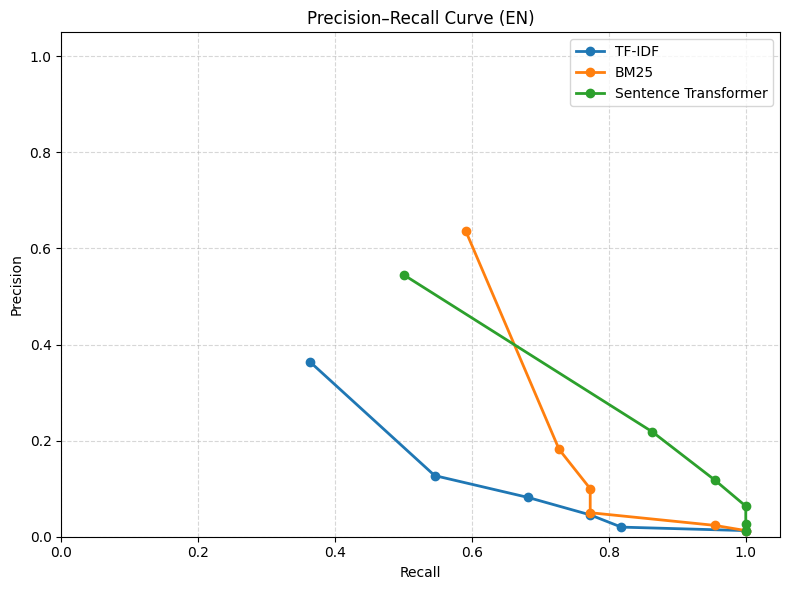

In [33]:
plot_precision_recall(en_details, "en")